# 04. 전체 실험 결과 정리와 해석

기준 모델(Task 2)과 본 실험(A·B·C × 3 seed)을 한 흐름으로 묶어, **무엇이 나왔고 왜 그렇게 나왔는지**를 정리한다.
모든 수치는 저장소에 커밋된 결과 파일(`result_task2/`, `result_full/make_v1/`)에서 다시 읽는다. 원본 이미지·GPU·재학습은 필요 없다.

## 0. 한눈에 보기

> **결론.** 이번 조건에서 제조사 계층은 전체 성능을 개선하지 못했다.
> - 다른 제조사로 틀리는 오류는 여전히 남아 있었다. 그러나 제안한 구조는 이 오류를 일관되게 줄이지 못했고, 같은 제조사 안의 오류는 늘었다.
> - 제조사 가중치는 B 대비 소수 제조사(BMW·GMC·VW) 성능을 3개 seed 모두에서 올렸고, Macro-F1·Balanced accuracy도 일부 개선했다. 그러나 기본 모델 A의 전체 성능을 넘지는 못했다.
> - 사전학습의 영향과 계층 구조의 한계는 후속 통제 실험으로 구분해야 한다.
>
> 이 노트북은 **관측**(데이터로 확인한 것)과 **가능한 설명**(아직 검증하지 않은 해석)을 구분해서 적는다.

| 질문 | 답 | 근거 |
|---|---|---|
| 기준 CNN은 얼마나 하나? | 검증 정확도 77%, Macro-F1 73%. 과적합이 뚜렷함 | §2 |
| 사전학습·증강을 쓰면? | 정확도 94.2%, Macro-F1 92.0% (A) | §3 |
| H1: 제조사 계층(B)이 A보다 나은가? | **아니오.** Macro-F1 −0.19%p, 3개 seed 모두 음수 | §3 |
| 가중치(C)가 전체 성능을 올리나? | **B 대비는 일부 개선, A는 못 넘음.** C − B: Macro-F1 +0.13%p(2/3), Balanced acc. +0.23%p. C − A: Macro-F1 −0.05%p(0/3) | §3 |
| 가중치가 소수 제조사를 돕나? | **예.** 가중치만 다른 C − B가 +1.42%p, 3개 seed 모두 양수 | §3, §4-3 |
| 왜 계층이 효과가 없었나? | **입증하지 못함.** 관측: 다른 제조사 오류(검증 이미지의 3.24%, 약 576장)를 B는 평균 약 8장만 줄였고 1개 seed에서는 오히려 늘었다. 같은 제조사 오류는 3개 seed 모두 늘었다. 원인 설명은 후보 단계 | §4 |

| 단계 | 내용 |
|---|---|
| **1. 실험 지도** | 실험별 조건, 같은 분할을 썼는지 확인 |
| **2. 기준 모델 (Task 2)** | 두 번 실행한 결과의 재현성, 과적합 |
| **3. 본 실험 성능** | 평균 ± 표준편차, 같은 seed끼리의 차이 |
| **4. 왜 개선이 없었나** | 오류 구조, 구제 vs 손해, 제조사별 득실, 남는 혼동 쌍 |
| **5. 해석과 다음 실험** | 적용 조건, 후속 실험 |
| **6. 한계** | 이 결과로 말할 수 없는 것 |

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

mpl.rcParams.update({"font.family": "AppleGothic", "axes.unicode_minus": False, "figure.dpi": 110,
                     "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 2)

FULL, T2 = Path("result_full/make_v1"), Path("result_task2")
MODELS = ["flat", "hierarchy", "hierarchy_make_weighted"]
NAME = {"flat": "A 단순 CNN", "hierarchy": "B 제조사 계층", "hierarchy_make_weighted": "C 계층+가중치"}
COL = {"flat": "#2F6DB5", "hierarchy": "#D9822B", "hierarchy_make_weighted": "#3A9D5D"}
BASE = {"동현 (GPU)": T2 / "baseline_seed0_DonghyunShin", "현일 (CPU)": T2 / "baseline_seed0_Hyeonil_Cho"}
SEEDS = [0, 1, 2]
MINORITY = ["volkswagen", "bmw", "gmc"]

def err_split(M, names):
    # 다른 제조사로 틀린 비율, 같은 제조사 안에서 틀린 비율 (분모 = 전체 검증 이미지)
    mk = np.array([n.split("/")[0] for n in names])
    off = M.copy(); np.fill_diagonal(off, 0)
    cross = off[mk[:, None] != mk[None, :]].sum()
    return cross / M.sum(), (off.sum() - cross) / M.sum()

per_run = pd.read_csv(FULL / "per_run.csv")
mean_std = pd.read_csv(FULL / "mean_std.csv").set_index("experiment")
class_info = pd.read_csv(FULL / "evidence/seed0/class_info.csv").sort_values("model_idx")
print("본 실험 실행 수:", len(per_run), "| 기준 모델 실행 수:", len(BASE))

본 실험 실행 수: 9 | 기준 모델 실행 수: 2


## 1. 실험 지도

| 실험 | 초기화 | 증강 | 학습 | 무엇을 보나 | 결과 위치 |
|---|---|---|---|---|---|
| **Task 2 기준 모델** ×2 (동현 GPU, 현일 CPU) | 무작위 | 없음 | Adam 3e-4, 12 epoch | 아무 기법 없는 출발점 | `result_task2/baseline_seed0_*` |
| **A 단순 CNN** × seed 0·1·2 | ImageNet | 크롭·반전·색 변화 | AdamW 3e-4, cosine, 30 epoch | 사전학습 비교 기준 | `result_full/make_v1` |
| **B 제조사 계층** × 3 | ImageNet | 〃 | 〃 | H1: 제조사 정보의 효과 (soft: 제조사 확률 × 제조사 내 차종 확률) | 〃 |
| **C 계층 + 가중치** × 3 | ImageNet | 〃 | 〃 | 소수 제조사 가중치(학습 빈도의 역제곱근)의 추가 효과 | 〃 |

- 모델은 모두 ResNet-18, 입력 224px, 배치 64이고, 50개 차종(10개 제조사 × 5)을 분류한다.
- 체크포인트는 **검증 Macro-F1이 가장 높은 epoch**를 쓴다. **테스트 세트는 아직 쓰지 않았다.**
- 같은 seed의 A·B·C는 초기화·데이터 순서·증강 난수가 같다. 그래서 "같은 seed끼리의 차이"를 공정하게 비교할 수 있다.

공정 비교의 전제는 **모든 실행이 같은 데이터 분할을 썼다는 것**이다. 분할 파일의 SHA-256으로 확인한다.
현일 실행은 Windows에서 Git이 줄바꿈을 CRLF로 바꿔 받아 해시가 달라 보인다. 그래서 저장소 파일을 CRLF로 바꿔 계산한 해시와도 비교한다. 내용은 같다.

In [2]:
hashes = {f"Task 2 · {k}": json.load(open(p / "config.json"))["split_sha256"] for k, p in BASE.items()}
hashes |= {f"본 실험 · seed {s}": json.load(open(FULL / f"evidence/seed{s}/config.json"))["split_sha256"] for s in SEEDS}
import hashlib
raw = {f: Path(f"splits/{f}").read_bytes() for f in ["train.csv", "val.csv", "test.csv", "class_info.csv"]}
lf = {f: hashlib.sha256(b).hexdigest() for f, b in raw.items()}
crlf = {f: hashlib.sha256(b.replace(b"\n", b"\r\n")).hexdigest() for f, b in raw.items()}  # Windows Git checkout
match = {k: "저장소와 같음 (LF)" if h == lf else "저장소와 같음 (CRLF 줄바꿈)" if h == crlf else "다름" for k, h in hashes.items()}
assert "다름" not in match.values(), match
display(pd.DataFrame(hashes).T.applymap(lambda h: h[:12] + "…").assign(판정=pd.Series(match)))
print("✅ 5개 설정 모두 저장소의 splits/와 같은 분할을 사용했다.")

,train.csv,val.csv,test.csv,class_info.csv,판정
Task 2 · 동현 (GPU),aa06009a4fea…,89c1e962480c…,91b55d4bf14d…,b7e2e25898d9…,저장소와 같음 (LF)
Task 2 · 현일 (CPU),91b23e443054…,9a12c73621df…,0e50f285472a…,216621a0d105…,저장소와 같음 (CRLF 줄바꿈)
본 실험 · seed 0,aa06009a4fea…,89c1e962480c…,91b55d4bf14d…,b7e2e25898d9…,저장소와 같음 (LF)
본 실험 · seed 1,aa06009a4fea…,89c1e962480c…,91b55d4bf14d…,b7e2e25898d9…,저장소와 같음 (LF)
본 실험 · seed 2,aa06009a4fea…,89c1e962480c…,91b55d4bf14d…,b7e2e25898d9…,저장소와 같음 (LF)


✅ 5개 설정 모두 저장소의 splits/와 같은 분할을 사용했다.


## 2. 기준 모델 (Task 2): 무작위 초기화, 증강 없음

같은 코드와 같은 seed로 **다른 컴퓨터(GPU / CPU)에서 두 번** 학습했다.

In [3]:
rows = []
for k, p in BASE.items():
    m = json.load(open(p / "metrics.json")); tr, va = m["train_at_best_checkpoint"], m["validation_at_best_checkpoint"]
    names = pd.read_csv(p / "confusion_matrix_counts.csv", index_col=0)
    cross, within = err_split(names.values, list(names.index))
    rows.append({"실행": k, "최적 epoch": m["best_epoch"], "학습 정확도": tr["accuracy"] * 100,
                 "검증 정확도": va["accuracy"] * 100, "검증 Macro-F1": va["macro_f1"] * 100,
                 "과적합 차이(%p)": (tr["accuracy"] - va["accuracy"]) * 100, "검증 loss": va["loss"],
                 "다른 제조사 오류(%)": cross * 100, "같은 제조사 오류(%)": within * 100})
base = pd.DataFrame(rows).set_index("실행")
display(base)

d = base.loc["동현 (GPU)"]
assert (round(100 - d["검증 정확도"], 1), round(d["다른 제조사 오류(%)"], 1), round(d["같은 제조사 오류(%)"], 1)) == (23.0, 16.8, 6.1)
print(f"두 실행의 차이: 정확도 {abs(base['검증 정확도'].diff().iloc[-1]):.2f}%p, Macro-F1 {abs(base['검증 Macro-F1'].diff().iloc[-1]):.2f}%p")

,최적 epoch,학습 정확도,검증 정확도,검증 Macro-F1,과적합 차이(%p),검증 loss,다른 제조사 오류(%),같은 제조사 오류(%)
실행,,,,,,,,
동현 (GPU),12,96.37,77.03,73.46,19.34,0.98,16.83,6.14
현일 (CPU),10,95.51,77.10,73.24,18.42,0.92,17.30,5.60


두 실행의 차이: 정확도 0.07%p, Macro-F1 0.21%p


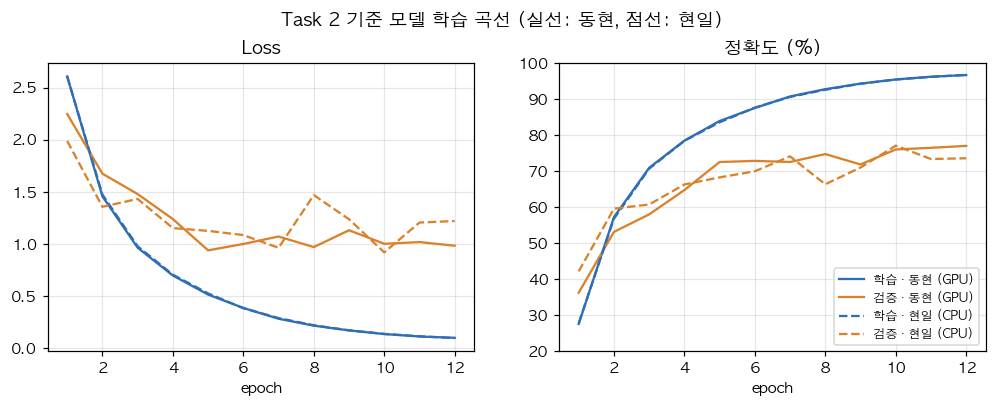

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for (k, p), ls in zip(BASE.items(), ["-", "--"]):
    h = pd.read_csv(p / "history.csv")
    ax[0].plot(h.epoch, h.train_loss, ls, color="#2F6DB5", label=f"학습 · {k}")
    ax[0].plot(h.epoch, h.val_loss, ls, color="#D9822B", label=f"검증 · {k}")
    ax[1].plot(h.epoch, h.train_accuracy * 100, ls, color="#2F6DB5", label=f"학습 · {k}")
    ax[1].plot(h.epoch, h.val_accuracy * 100, ls, color="#D9822B", label=f"검증 · {k}")
ax[0].set(title="Loss", xlabel="epoch"); ax[1].set(title="정확도 (%)", xlabel="epoch", ylim=(20, 100))
ax[1].legend(fontsize=8, loc="lower right")
fig.suptitle("Task 2 기준 모델 학습 곡선 (실선: 동현, 점선: 현일)", y=1.02); plt.show()

**해석**
- **재현이 됩니다.** 다른 하드웨어에서 돌려도 정확도는 0.1%p, Macro-F1은 0.2%p만 다르다. 이후 비교의 출발점으로 믿을 수 있다.
- **과적합이 뚜렷하다.** 학습 정확도 95~96%, 검증 77%로 약 19%p 차이가 난다. 검증 loss는 5 epoch 무렵부터 더 줄지 않는다.
- **오답의 73~76%가 "다른 제조사"로 틀린 경우다.** 동현 기준으로 검증 이미지의 16.8%가 다른 제조사 오류이고, 전체 오류율 23.0%의 73%를 차지한다.
  - 가능한 설명: 처음부터 학습한 CNN이 엠블럼·그릴 같은 제조사 단서보다 차의 전체 모양에 기댄다. 사진 검토로 확인하지는 않았다.

## 3. 본 실험 성능: A·B·C × 3 seed

단위는 %이고, ±는 seed 3개의 표본 표준편차다.

In [5]:
metrics = {"accuracy": "정확도", "macro_f1": "Macro-F1", "balanced_accuracy": "Balanced acc.",
           "top3_accuracy": "Top-3", "minority_make_fine_accuracy": "소수 제조사 차종 정확도"}
again = per_run.groupby("experiment")[list(metrics)].agg(["mean", "std"])
for m in metrics:  # 저장된 집계와 원자료 재계산이 같은지 확인
    assert np.allclose(again[(m, "mean")].loc[MODELS], mean_std.loc[MODELS, f"{m}_mean"])
table = pd.DataFrame({lab: [f"{again.loc[e, (m, 'mean')] * 100:.2f} ± {again.loc[e, (m, 'std')] * 100:.2f}" for e in MODELS]
                      for m, lab in metrics.items()}, index=[NAME[e] for e in MODELS])
display(table)

,정확도,Macro-F1,Balanced acc.,Top-3,소수 제조사 차종 정확도
A 단순 CNN,94.22 ± 0.06,92.02 ± 0.09,91.63 ± 0.21,98.58 ± 0.02,86.27 ± 0.29
B 제조사 계층,94.07 ± 0.11,91.83 ± 0.21,91.39 ± 0.26,98.58 ± 0.06,85.66 ± 0.78
C 계층+가중치,94.04 ± 0.14,91.96 ± 0.10,91.62 ± 0.12,98.52 ± 0.08,87.08 ± 0.38


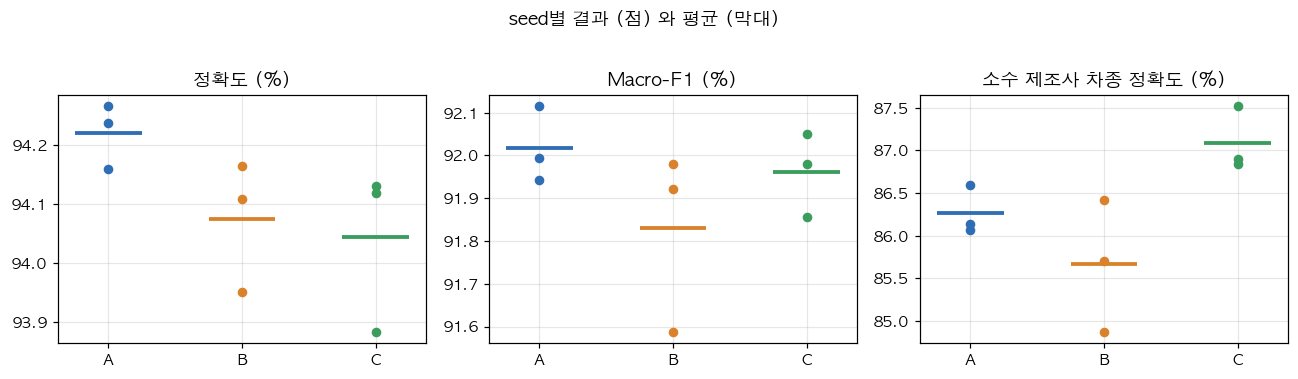

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, m in zip(axes, ["accuracy", "macro_f1", "minority_make_fine_accuracy"]):
    for i, e in enumerate(MODELS):
        v = per_run[per_run.experiment == e].sort_values("seed")[m] * 100
        ax.scatter([i] * 3, v, color=COL[e], s=28, zorder=3)
        ax.hlines(v.mean(), i - 0.25, i + 0.25, color=COL[e], lw=2.5)
    ax.set_xticks(range(3), ["A", "B", "C"]); ax.set_title(metrics[m] + " (%)")
fig.suptitle("seed별 결과 (점) 와 평균 (막대)", y=1.03); plt.tight_layout(); plt.show()

같은 seed의 모델끼리는 초기화와 데이터 순서가 같으므로, **같은 seed끼리의 차이**가 가장 공정한 비교다.

,정확도,Macro-F1,소수 제조사 차종 정확도,다른 제조사 오류율,같은 제조사 오류율
비교,,,,,
B - A,-0.15 (0/3),-0.19 (0/3),-0.61 (0/3),-0.05 (1/3),+0.19 (3/3)
C - A,-0.18 (0/3),-0.05 (0/3),+0.81 (3/3),-0.03 (1/3),+0.21 (3/3)
C - B,-0.03 (1/3),+0.13 (2/3),+1.42 (3/3),+0.02 (1/3),+0.02 (1/3)


단위 %p. 괄호는 차이가 양수였던 seed 수. 오류율은 양수가 '나빠짐'이다.


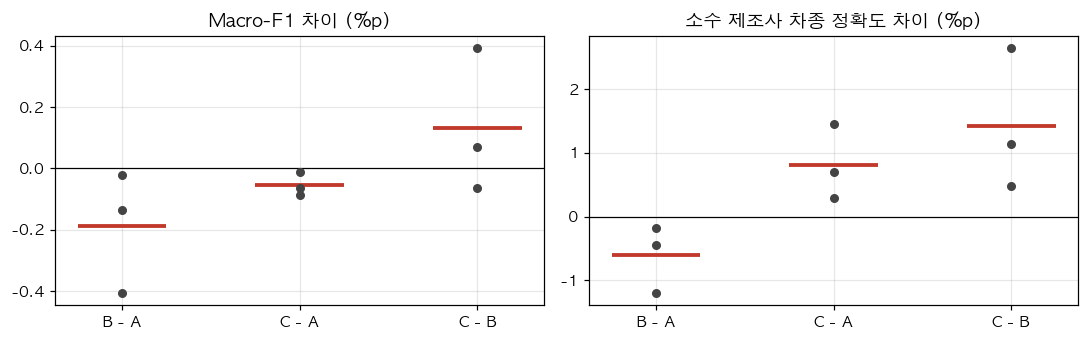

In [7]:
paired = pd.read_csv(FULL / "paired_deltas_pp.csv")
comps = {"hierarchy minus flat": "B - A", "hierarchy_make_weighted minus flat": "C - A",
         "hierarchy_make_weighted minus hierarchy": "C - B"}
show = ["accuracy", "macro_f1", "minority_make_fine_accuracy", "cross_make_error_rate", "within_make_error_rate"]
lab = {**metrics, "cross_make_error_rate": "다른 제조사 오류율", "within_make_error_rate": "같은 제조사 오류율"}
summary = []
for c, short in comps.items():
    g = paired[paired.comparison == c]
    summary.append({"비교": short, **{lab[m]: f"{g[m].mean():+.2f}  ({(g[m] > 0).sum()}/3)" for m in show}})
display(pd.DataFrame(summary).set_index("비교"))
print("단위 %p. 괄호는 차이가 양수였던 seed 수. 오류율은 양수가 '나빠짐'이다.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, m in zip(axes, ["macro_f1", "minority_make_fine_accuracy"]):
    for i, (c, short) in enumerate(comps.items()):
        v = paired[paired.comparison == c].sort_values("seed")[m]
        ax.scatter([i] * 3, v, color="#444", s=24, zorder=3); ax.hlines(v.mean(), i - 0.25, i + 0.25, color="#C0392B", lw=2.5)
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(3), list(comps.values())); ax.set_title(f"{lab[m]} 차이 (%p)")
plt.tight_layout(); plt.show()

**해석**
- **H1(제조사 계층이 낫다)은 지지되지 않는다.** B − A의 Macro-F1은 평균 −0.19%p이고 3개 seed 모두 음수다. 정확도도 3개 seed 모두 낮다.
- **가중치의 효과는 C − B로 본다.** B와 C의 차이는 가중치 하나뿐이기 때문이다.
  - 소수 제조사 차종 정확도: **+1.42%p, 3개 seed 모두 양수.** 이번 실험에서 가장 일관된 효과다.
  - Macro-F1 +0.13%p(2/3), Balanced accuracy +0.23%p, 정확도 −0.03%p. 계층형에서 잃은 몫을 일부 되찾았지만 A를 넘지는 못했다.
  - C − A의 +0.81%p는 계층과 가중치를 **함께** 적용한 결과다. 가중치만의 효과로 읽으면 안 된다.
- **A 대비 전체 성능은 개선되지 않았다.** C − A의 Macro-F1은 −0.05%p로 3개 seed 모두 음수다.
- **차이의 크기:** seed 간 표준편차(0.1~0.2%p)와 비슷한 수준이다. **"관측된 차이는 작고, 전체 개선은 확인되지 않았다"**가 정확한 표현이다. seed 3개로는 "같다(동등하다)"는 것도 입증하지 못한다.
- 계획서의 개선 기준(Macro-F1 +2%p, 3회 중 2회 이상 개선)은 충족하지 못했다.

## 4. 왜 개선이 없었나: 관측과 가능한 설명

### 4-1. 오류 구조: 다른 제조사 오류 vs 같은 제조사 오류

제조사 계층이 **직접 겨냥하는** 오류는 "다른 제조사의 차종으로 틀리는 오류"다. 같은 제조사 안의 차종 혼동은 제조사 정보만으로 자동으로 풀리지 않는다.
다만 공동 학습이 특징 표현을 바꾸므로, 같은 제조사 안의 오류에도 간접적인 영향(좋든 나쁘든)은 있을 수 있다.

**분모를 섞지 않도록 두 가지 기준을 함께 표시한다.**
- **검증 이미지 대비(%)**: 전체 17,771장 중 몇 %가 그 오류인가
- **오답 중 비중(%)**: 틀린 이미지 중 몇 %가 그 오류인가

,다른 제조사 (검증 이미지 대비 %),같은 제조사 (검증 이미지 대비 %),전체 오류율 (%),다른 제조사 (장),오답 중 다른 제조사 비중(%)
Task 2 · 동현 (GPU),16.83,6.14,22.97,2991,73.27
Task 2 · 현일 (CPU),17.30,5.60,22.90,3075,75.55
A 단순 CNN,3.24,2.54,5.78,576,56.12
B 제조사 계층,3.20,2.73,5.93,568,53.97
C 계층+가중치,3.21,2.74,5.96,571,53.95


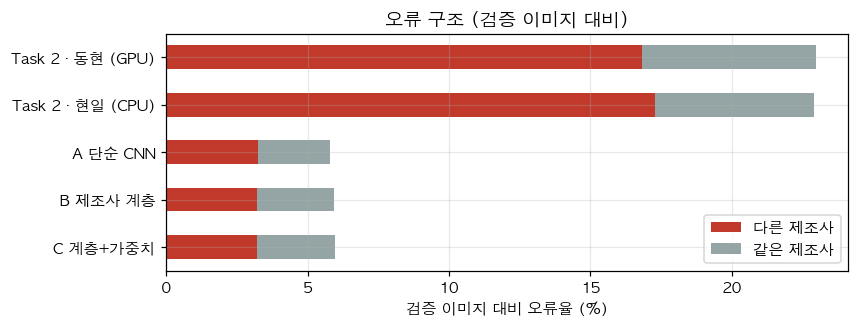

In [8]:
# 저장된 오류 분해가 혼동 행렬과 일치하는지 한 번 확인
names = class_info.make_model.tolist()
c0, w0 = err_split(np.load(FULL / "evidence/seed0/flat/validation_confusion.npy"), names)
r0 = per_run.query("seed == 0 and experiment == 'flat'").iloc[0]
assert np.isclose(c0, r0.cross_make_error_rate) and np.isclose(w0, r0.within_make_error_rate)

err = pd.DataFrame({**{f"Task 2 · {k}": {"다른 제조사": base.loc[k, "다른 제조사 오류(%)"], "같은 제조사": base.loc[k, "같은 제조사 오류(%)"]} for k in BASE},
                    **{NAME[e]: {"다른 제조사": mean_std.loc[e, "cross_make_error_rate_mean"] * 100,
                                 "같은 제조사": mean_std.loc[e, "within_make_error_rate_mean"] * 100} for e in MODELS}}).T
err["전체 오류"] = err.sum(axis=1)
err["다른 제조사 (장)"] = (err["다른 제조사"] / 100 * 17771).round().astype(int)
err["오답 중 다른 제조사 비중(%)"] = err["다른 제조사"] / err["전체 오류"] * 100
err = err.rename(columns={"다른 제조사": "다른 제조사 (검증 이미지 대비 %)", "같은 제조사": "같은 제조사 (검증 이미지 대비 %)",
                          "전체 오류": "전체 오류율 (%)"})
display(err)
a = err.loc[NAME["flat"]]
assert round(a["다른 제조사 (검증 이미지 대비 %)"], 2) == 3.24 and round(a["오답 중 다른 제조사 비중(%)"], 1) == 56.1

ax = err.iloc[:, :2].plot.barh(stacked=True, figsize=(8, 2.8), color=["#C0392B", "#95A5A6"])
ax.invert_yaxis(); ax.legend(["다른 제조사", "같은 제조사"])
ax.set(xlabel="검증 이미지 대비 오류율 (%)", title="오류 구조 (검증 이미지 대비)")
plt.show()

**관측**
- 다른 제조사 오류(검증 이미지 대비)는 기준 모델 16.83%에서 A 3.24%로 크게 줄었다. 오답 중 비중으로는 73.3% → 56.1%다.
- 그래도 A에서 **약 576장(오답의 56%)**이 여전히 다른 제조사 오류다. 계층형이 겨냥할 오류는 **충분히 남아 있었다.**
- B·C는 이 오류를 평균 0.03~0.05%p(약 5~8장)만 줄였다. 3개 seed 중 2개에서 줄고 1개에서 늘어, 방향도 일관되지 않다. 반면 같은 제조사 오류는 약 0.2%p(약 35장) 늘었고, 3개 seed 모두에서 늘었다.
- 즉 **제안한 구조는 남아 있던 다른 제조사 오류를 일관되게 줄이지 못했다.**

**가능한 설명 (검증 안 됨)**
- **정보 중복:** A는 제조사 정확도가 이미 약 96.8%다. 별도 제조사 머리가 주는 추가 정보가 적었을 수 있다.
- **남은 오류의 성격:** A의 다른 제조사 오류 중 **GMC ↔ Chevrolet 브랜드 사이 오류는 약 23%(132장)**다. 그중 명시한 **형제차 쌍(Sierra ↔ Silverado, Yukon ↔ Tahoe 네 방향)의 오류는 약 123장으로, 전체 다른 제조사 오류의 21.3%**다(§4-4). 다른 제조사 혼동 상위 4쌍도 모두 이 형제차 쌍이다. 형제차는 제조사 판단 자체가 불확실해서 제조사 단계가 도움이 안 될 수 있다.
  - 나머지 오류의 대표 사례로는 F-150 → Silverado, Corolla → Civic 등이 있다. 나머지 전체의 성격은 확인하지 않았다.
- **공동 학습의 부작용:** 제조사 손실을 함께 학습하면서 차종 구분에 쓰이던 표현이 바뀌어, 같은 제조사 오류가 늘었을 수 있다.
- **사전학습 vs 다른 요인:** 기준 모델과 A는 사전학습뿐 아니라 증강·optimizer·학습률 스케줄·epoch·전처리가 **함께** 다르다. 16.83% → 3.24%의 감소를 사전학습 효과로 단정할 수 없다. 무작위 초기화 조건에서 계층형이 더 도움이 되는지도 검증되지 않은 가설이다(§5의 2×2 실험).

### 4-2. 같은 이미지에서 무슨 일이 있었나: 구제 vs 손해

두 모델을 같은 검증 이미지에서 비교한다. **구제**는 기존 모델이 틀리고 새 모델이 맞힌 이미지, **손해**는 그 반대다.

In [9]:
tr = pd.read_csv(FULL / "prediction_transitions.csv")
tr["비교"] = tr.comparison.map(comps)
agg = tr.groupby("비교")[["rescued", "harmed", "both_wrong"]].mean().reindex(comps.values())
agg["순변화"] = agg.rescued - agg.harmed
agg = agg.rename(columns={"rescued": "구제", "harmed": "손해", "both_wrong": "둘 다 틀림"})
display(agg.round(1))
print("seed 3개 평균, 단위 = 이미지 수 (검증 17,771장)")

,구제,손해,둘 다 틀림,순변화
비교,,,,
B - A,350.0,376.0,677.0,-26.0
C - A,359.7,391.0,667.3,-31.3
C - B,350.7,356.0,702.3,-5.3


seed 3개 평균, 단위 = 이미지 수 (검증 17,771장)


**해석**
- 모델을 바꿀 때마다 약 **350장을 새로 맞히고, 약 370장을 새로 틀린다.** 순변화는 수십 장 수준이다.
- 즉 **오답 집합은 달라졌지만, 전체 정확도 개선으로 이어지지는 않았다.** 그렇다고 바뀐 것이 무의미하다는 뜻은 아니다. C에서는 그 변화의 일부가 소수 제조사 성능 향상으로 나타났다(§4-3).
- 표의 "둘 다 틀림"(약 670~700장)은 **비교한 두 모델이 같은 seed에서 함께 틀린 이미지 수의 seed 평균**이다. 세 모델·세 seed 전체의 공통 오답은 아래에서 따로 센다.
- A가 틀리는 약 1,030장 중 **약 1/3(350장)은 B가 맞힌다.** 앙상블이 효과를 낼 수 있다는 신호이기도 하다. 단, 아직 실험하지 않았다.

In [10]:
W = {}
for s in SEEDS:
    idx = pd.read_csv(FULL / f"evidence/seed{s}/validation_index.csv")
    for e in MODELS:
        pr = pd.read_csv(FULL / f"evidence/seed{s}/{e}/validation_predictions.csv")
        assert (pr.target.values == idx.model_idx.values).all()  # 같은 이미지 순서
        W[(s, e)] = (pr.prediction != pr.target).values
all9, any9 = np.logical_and.reduce(list(W.values())), np.logical_or.reduce(list(W.values()))
print(f"9회 실행 모두 틀린 이미지: {all9.sum()}장 | 한 번 이상 틀린 이미지: {any9.sum()}장 | 실행에 따라 정답 여부가 바뀐 이미지: {(any9 & ~all9).sum()}장")
assert (all9.sum(), any9.sum()) == (321, 2324)
hard_cls = idx.loc[all9, "make_model"].value_counts().head(8)
display(hard_cls.rename("9회 모두 틀린 이미지 수").to_frame())

9회 실행 모두 틀린 이미지: 321장 | 한 번 이상 틀린 이미지: 2324장 | 실행에 따라 정답 여부가 바뀐 이미지: 2003장


,9회 모두 틀린 이미지 수
make_model,
jeep/cherokee,35
gmc/sierra_1500,31
dodge/ram_1500,23
bmw/328i,22
chevrolet/silverado,16
chevrolet/tahoe,13
gmc/yukon_1500,12
volkswagen/golf,11


- **9회 실행 모두에서 틀린 이미지는 321장**이다. 구조·seed와 상관없이 일관되게 어려운 이미지다.
  - 원인 후보는 형제차, 라벨 오류, 가림, 저해상도, 배경, 크롭 문제 등이다. 사진을 직접 보지 않았으므로 어느 쪽인지는 모른다.
  - **다음 단계로는 새 학습보다 이 321장과 주요 혼동 쌍의 사진 검토를 먼저 권한다**(§5).
- 반대로 한 번 이상 틀린 이미지는 2,324장이다. **그중 2,003장은 실행에 따라 정답 여부가 달라졌다.** 이 이미지들이 결정 경계 근처에 있는지는 확인하지 않았다.

### 4-3. 제조사별 득실: 가중치는 누구에게서 누구에게 옮겼나

,학습 이미지,A 차종 정확도,B - A (%p),C - A (%p),"C - B (%p, 가중치 효과)"
make,,,,,
ford,15401,97.51,-0.20,-0.42,-0.22
honda,13348,97.22,0.05,-0.19,-0.23
chevrolet,11834,93.30,0.30,-0.55,-0.85
toyota,10000,96.08,-0.22,-0.50,-0.28
nissan,9257,95.75,-0.24,-0.32,-0.08
dodge,6397,89.25,-0.41,0.10,0.51
jeep,5370,92.82,-0.09,-0.03,0.06
volkswagen,5347,93.72,0.03,0.29,0.26
gmc,3298,81.61,-1.56,1.74,3.30


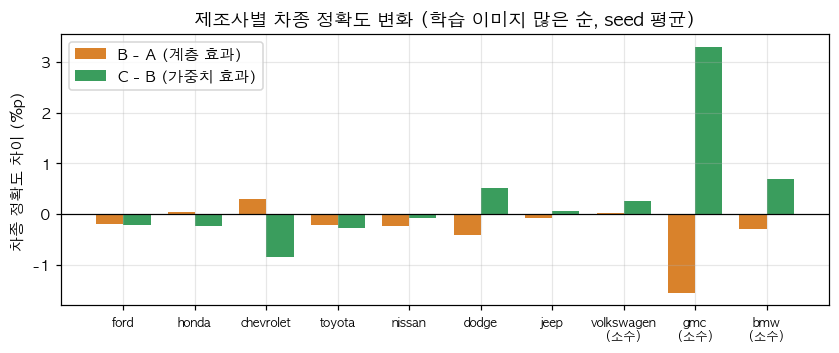

In [11]:
pm = pd.read_csv(FULL / "per_make.csv")
fine = pm.pivot_table(index="make", columns="experiment", values="fine_accuracy", aggfunc="mean") * 100
n_train = class_info.groupby("make").n_train.sum()
fine = fine.loc[n_train.sort_values(ascending=False).index]
delta = pd.DataFrame({"학습 이미지": n_train, "A 차종 정확도": fine.flat,
                      "B - A (%p)": fine.hierarchy - fine.flat, "C - A (%p)": fine.hierarchy_make_weighted - fine.flat,
                      "C - B (%p, 가중치 효과)": fine.hierarchy_make_weighted - fine.hierarchy}).loc[fine.index]
display(delta.round(2))

fig, ax = plt.subplots(figsize=(9, 3.2))
x = np.arange(len(fine)); w = 0.38
ax.bar(x - w / 2, delta["B - A (%p)"], w, color=COL["hierarchy"], label="B - A (계층 효과)")
ax.bar(x + w / 2, delta["C - B (%p, 가중치 효과)"], w, color=COL["hierarchy_make_weighted"], label="C - B (가중치 효과)")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x, [f"{m}\n{'(소수)' if m in MINORITY else ''}" for m in fine.index], fontsize=8)
ax.set(ylabel="차종 정확도 차이 (%p)", title="제조사별 차종 정확도 변화 (학습 이미지 많은 순, seed 평균)"); ax.legend()
plt.show()

**관측**
- **가중치 효과(C − B):** GMC +3.30, BMW +0.70, Dodge +0.51, VW +0.26%p로 올랐다. 가장 큰 이득은 형제차 문제가 있는 GMC에서 나온다.
  - 오른 곳이 소수 제조사만은 아니다. Dodge는 소수 제조사로 정하지 않았지만 VW보다 더 올랐다.
- 대신 Chevrolet(−0.85)·Toyota·Honda·Ford(−0.2~−0.3%p)처럼 이미지가 많은 제조사가 내려갔다. 이득이 GMC·BMW 쪽으로 옮겨진 모양이고, 전체 합은 거의 그대로다. 가장 많이 내려간 Chevrolet이 GMC의 형제 브랜드라는 점은 §4-4와 연결된다.
- **계층 효과(B − A):** GMC가 −1.56%p로 가장 크게 손해를 본다. "형제차에서 제조사 계층이 가장 크게 실패한다"는 Activity 1 예측(H2)과 같은 방향이다. 다만 하나의 관측일 뿐이다.
- 그래서 C의 가치는 "전체 1등"이 아니라 **"소수 집단의 성능이 중요한 사용 목적"**에서 판단해야 한다. 예를 들면 특정 브랜드를 놓치면 비용이 큰 경우다.

### 4-4. 끝까지 남는 혼동 쌍

seed 3개 평균 오분류 장수다. A의 상위 10쌍을 B·C와 나란히 비교한다.

In [12]:
cp = pd.read_csv(FULL / "confusion_pairs.csv")
pairs = cp.groupby(["true_class", "predicted_class", "same_make", "experiment"])["count"].sum().div(3).unstack("experiment").fillna(0)
top = pairs.sort_values("flat", ascending=False).head(10)[MODELS].rename(columns=NAME).round(1)
display(top)
print(f"A의 상위 10쌍 중 같은 제조사 쌍: {top.index.get_level_values('same_make').to_numpy().sum()}개")
twin = pairs.loc[[("gmc/sierra_1500", "chevrolet/silverado", False), ("chevrolet/silverado", "gmc/sierra_1500", False)], MODELS]
display(pd.concat([twin, twin.sum().to_frame("양방향 합계").T]).rename(columns=NAME).round(1))
assert round(twin.flat.sum(), 1) == 87.7 and round(twin.hierarchy_make_weighted.sum(), 1) == 86.3

cross = cp[~cp.same_make].copy()
cross["형제 브랜드(GMC↔Chevrolet)"] = [{t.split("/")[0], q.split("/")[0]} == {"gmc", "chevrolet"} for t, q in zip(cross.true_class, cross.predicted_class)]
share = cross.groupby("experiment").apply(lambda d: d.loc[d["형제 브랜드(GMC↔Chevrolet)"], "count"].sum() / d["count"].sum() * 100)
print("다른 제조사 오류 중 GMC↔Chevrolet 브랜드 간 비중(%):", share.rename(NAME).round(1).to_dict())
TWINS = {("gmc/sierra_1500", "chevrolet/silverado"), ("chevrolet/silverado", "gmc/sierra_1500"),
         ("gmc/yukon_1500", "chevrolet/tahoe"), ("chevrolet/tahoe", "gmc/yukon_1500")}
a_cross = cross[cross.experiment == "flat"]
tw = a_cross[[(t, q) in TWINS for t, q in zip(a_cross.true_class, a_cross.predicted_class)]]["count"].sum() / 3
print(f"A: 형제차 쌍 4방향 오류 {tw:.1f}장 = 다른 제조사 오류의 {tw / (a_cross['count'].sum() / 3) * 100:.1f}%")
assert round(tw, 1) == 123.0
top_cross = cross[cross.experiment == "flat"].groupby(["true_class", "predicted_class"])["count"].sum().div(3).sort_values(ascending=False).head(6)
display(top_cross.rename("A의 다른 제조사 혼동 상위 (장, seed 평균)").to_frame().round(1))

,,experiment,A 단순 CNN,B 제조사 계층,C 계층+가중치
true_class,predicted_class,same_make,,,
gmc/sierra_1500,chevrolet/silverado,False,55.0,61.7,49.3
dodge/ram_1500,dodge/ram_2500,True,45.7,48.0,39.7
jeep/cherokee,jeep/grand_cherokee,True,42.7,43.3,43.3
dodge/ram_2500,dodge/ram_1500,True,41.7,38.0,41.0
bmw/328i,bmw/325i,True,36.7,36.3,36.3
chevrolet/silverado,gmc/sierra_1500,False,32.7,29.3,37.0
chevrolet/tahoe,chevrolet/silverado,True,22.0,21.7,20.3
gmc/yukon_1500,chevrolet/tahoe,False,22.0,22.0,17.0
bmw/325i,bmw/328i,True,22.0,25.0,20.3


A의 상위 10쌍 중 같은 제조사 쌍: 7개


experiment,A 단순 CNN,B 제조사 계층,C 계층+가중치
"(gmc/sierra_1500, chevrolet/silverado, False)",55.0,61.7,49.3
"(chevrolet/silverado, gmc/sierra_1500, False)",32.7,29.3,37.0
양방향 합계,87.7,91.0,86.3


다른 제조사 오류 중 GMC↔Chevrolet 브랜드 간 비중(%): {'A 단순 CNN': 23.0, 'B 제조사 계층': 24.1, 'C 계층+가중치': 23.0}
A: 형제차 쌍 4방향 오류 123.0장 = 다른 제조사 오류의 21.3%


,,"A의 다른 제조사 혼동 상위 (장, seed 평균)"
true_class,predicted_class,
gmc/sierra_1500,chevrolet/silverado,55.0
chevrolet/silverado,gmc/sierra_1500,32.7
gmc/yukon_1500,chevrolet/tahoe,22.0
chevrolet/tahoe,gmc/yukon_1500,13.3
ford/f150,chevrolet/silverado,10.0
toyota/corolla,honda/civic,9.3


**해석**
- 상위 쌍은 Activity 1에서 예측한 **"닮은 차종"** 그대로다.
  - **형제차:** Sierra → Silverado
  - **같은 차의 크기 차이:** Ram 1500 ↔ 2500
  - **같은 시리즈의 트림:** BMW 325i ↔ 328i
  - **같은 제조사의 비슷한 세단:** Civic ↔ Accord 등
- 상위 10쌍 중 7쌍이 **같은 제조사 안**(Ram, Jeep, BMW, Chevrolet)이다. 이번 실험에서 B는 이 오류를 줄이지 못했다(Ram 1500→2500은 45.7 → 48.0장으로 오히려 늘었다).
  - 제조사 정보만으로 이 오류가 자동으로 풀리지는 않는다. 다만 공동 학습으로 간접 효과가 생길 수는 있으므로 "원리상 불가능"이라고 단정하지는 않는다.
- **제조사가 다른 형제차 Sierra ↔ Silverado**가 가장 큰 오류다.
  - B는 Sierra→Silverado를 55.0 → 61.7장으로 더 틀렸다. 양방향 합계도 87.7 → 91.0장으로 늘었다.
  - C는 Sierra→Silverado를 49.3장으로 줄였지만, 반대 방향 Silverado→Sierra는 32.7 → 37.0장으로 늘었다. **한 방향의 개선과 반대 방향의 악화가 대부분 상쇄돼**, 양방향 합계는 87.7 → 86.3장으로 조금만 줄었다.

## 5. 해석과 다음 실험

### 확인된 것 (관측)
1. **기준 모델 → A:** 정확도 77% → 94%, Macro-F1 73% → 92%. 가장 큰 개선은 계층 구조가 아니라 **사전학습·증강·학습 설정을 함께 바꾼 묶음**에서 나왔다. 그중 어느 요소의 효과인지는 분리하지 못했다.
2. **제조사 계층(soft)은 전체 성능을 올리지 못했다.** 다른 제조사 오류는 A에서도 약 576장 남아 있었다. 그러나 B는 이를 일관되게 줄이지 못했고, 같은 제조사 오류는 늘었다.
3. **제조사 가중치(C − B)는 소수 제조사 성능을 3개 seed 모두에서 올렸다.** Macro-F1·Balanced accuracy도 B보다 일부 나아졌지만, 기본 모델 A의 전체 성능을 넘지는 못했다. 가중치는 소수 집단 성능이 중요한 목적에서 별도로 평가해야 한다.
4. **가장 많이 남는 오류는 같은 제조사 안의 닮은 차종과 형제차다.**

### 아직 설명하지 못한 것
- 계층형이 왜 다른 제조사 오류를 줄이지 못했는지: 정보 중복, 형제차의 제조사 불확실성, 공동 학습의 부작용 중 어느 것인지 이번 실험으로는 구분할 수 없다.
- 사전학습이 계층형의 이득을 줄였는지 여부.

### 계층형이 도움이 될 조건 (가설)
- 상위 그룹이 **시각적으로 뚜렷이 구분**되고, 기본 모델이 **상위 그룹부터 자주 틀리는** 경우. 예: 무작위 초기화, 적은 데이터
- 상위 그룹이 실제 혼동 구조와 맞는 경우. 제조사보다 **혼동 기반 그룹**이나 **차체 유형**이 더 나을 수 있다(Activity 1의 H2).

### 다음 단계 (하나씩 바꾸고, 같은 분할과 지표로 비교)
| 우선 | 할 일 | 확인할 것 |
|---|---|---|
| 0 | **오답 사진 검토** (9회 모두 틀린 321장, 주요 혼동 쌍, B가 새로 틀린 사례) | 형제차·라벨 오류·가림·저해상도 중 무엇이 많은지. 원인을 좁혀야 다음 실험을 고를 수 있다. 학습 비용이 없어 가장 먼저 한다 |
| 1 | **사전학습 × 계층 2×2** (무작위/ImageNet × A/B, 나머지 설정은 고정) | 계층의 이득이 사전학습 여부에 따라 달라지는가? (§4-1 설명 후보의 직접 검증) |
| 2 | **혼동 기반 그룹·차체 유형 계층** | 그룹은 **학습 데이터 내부**(학습 세트를 나눈 내부 검증 또는 out-of-fold 예측)에서 만든다. 외부 검증 세트는 모델 선택에만 쓴다. 같은 검증 세트로 그룹을 설계하고 평가까지 하면 평가가 설계에 오염된다 |
| 3 | **고해상도 입력**(320~384px, 비율 유지) | 엠블럼·그릴 단서로 형제차·트림 쌍이 줄어드는가? |
| 4 | **차종 단위 가중치**(Cui β) | 제조사 단위보다 소수 차종(Patriot, 528i, Golf)에 직접 효과가 있는가? |
| 5 | **A·B 앙상블** | §4-2의 "다르게 틀린다"를 실제 이득으로 바꿀 수 있는가? |

**Activity 1 계획과의 차이**
- 이번 계층은 **soft 결합**(제조사 확률 × 차종 확률)이다. Activity 1 보고서에 쓴 hard routing과 차체 유형·혼동 기반 계층은 아직 실험하지 않았다.

## 6. 한계: 이 결과로 말할 수 없는 것

- **검증 세트 기준이다.** 체크포인트도 검증 Macro-F1로 골랐으므로 수치가 약간 낙관적일 수 있다. 최종 주장은 테스트 세트 평가 뒤에 한다.
- **같은 분할에서 seed만 바꾼 3회**다. 학습 변동성은 보지만, 분할에 따른 변동이나 통계적 유의성은 입증하지 못한다. 차이가 작다고 해서 "동등함"이 입증된 것도 아니다.
- **근접 중복**(비슷한 재업로드 사진)은 검사하지 않았다. 정확히 같은 파일(MD5) 중복만 분할을 넘지 않게 처리했다.
- 기준 모델과 본 실험은 사전학습·증강·optimizer·epoch이 함께 다르다. 77% → 94%의 개선이 **어느 요소 덕분인지는 분리하지 못했다.**
- §4의 "가능한 설명"은 오류 분포에서 끌어낸 **후보**이고, 입증된 원인이 아니다. 형제차·라벨 오류·가림·저해상도 등은 사진을 직접 검토해야 구분할 수 있다.

### 재현
- 이 노트북: 저장소 루트에서 `python3 -m jupyter nbconvert --to notebook --execute --inplace 04_results_analysis.ipynb`
- 원자료: `result_full/make_v1/` (실행별 증빙은 `evidence/`, 학습 소스는 `sources/`), `result_task2/baseline_seed0_*/`
- 상세 결과집: [`result_full/make_v1/README.md`](result_full/make_v1/README.md)